In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


img = cv2.imread("WorldView_1-1_PAN.png", cv2.IMREAD_GRAYSCALE)


filtro_media = np.array([[1, 1, 1],
                         [1, 1, 1],
                         [1, 1, 1]], dtype=float)

filtro_media_img = np.array([[1, 1, 1],
                             [1, 2, 1],
                             [1, 1, 1]], dtype=float)

filtro_gauss = np.array([[1, 2, 1],
                         [2, 4, 2],
                         [1, 2, 1]], dtype=float)

In [4]:
def filtro(img, cf):
    if isinstance(img, str):
        img = cv2.imread(img, cv2.IMREAD_GRAYSCALE)
    
    if img is None:
        raise ValueError("No se pudo leer la imagen")

    filas, columnas = img.shape

    m, n = cf.shape
    oF = m // 2
    oC = n // 2

    suma_cf = np.sum(cf)
    if suma_cf != 0:
        cf = cf / suma_cf

    salida = np.zeros_like(img, dtype=float)

    for i in range(oF, filas - oF):
        for j in range(oC, columnas - oC):
            region = img[i - oF:i + oF + 1, j - oC:j + oC + 1]
            salida[i, j] = np.sum(region * cf)

    salida = np.clip(salida, 0, 255).astype(np.uint8)

    return salida

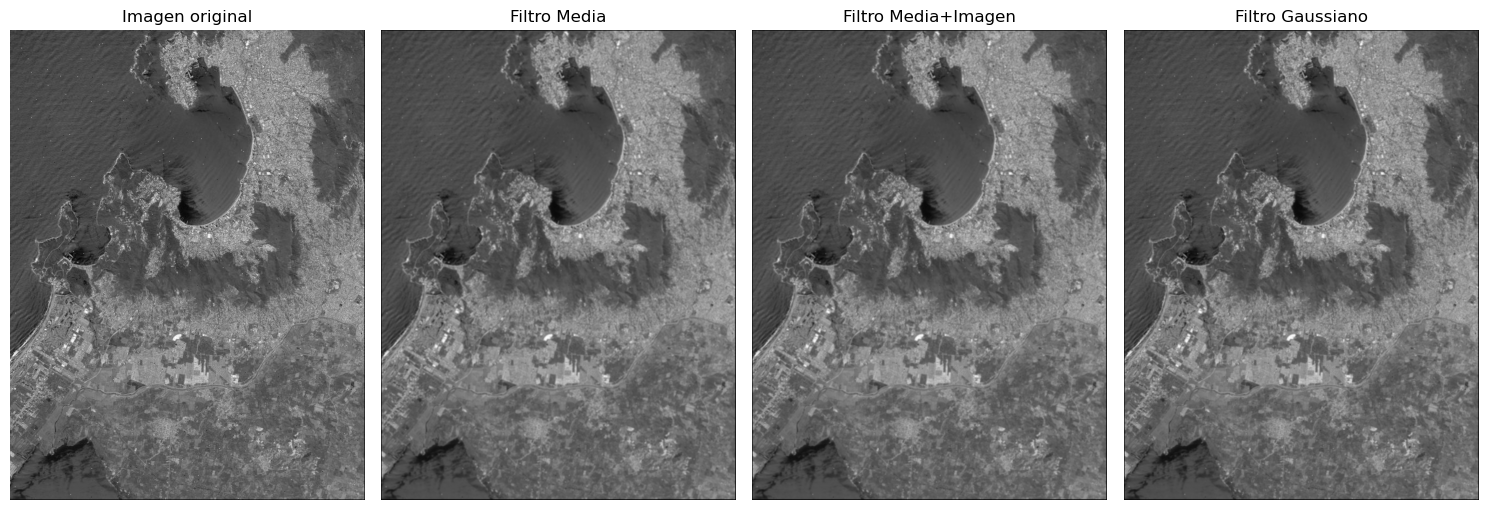

In [5]:
img_media = filtro(img, filtro_media)
img_media_img = filtro(img, filtro_media_img)
img_gauss = filtro(img, filtro_gauss)


plt.figure(figsize=(15, 5))

plt.subplot(1, 4, 1)
plt.imshow(img, cmap='gray')
plt.title("Imagen original")
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(img_media, cmap='gray')
plt.title("Filtro Media")
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(img_media_img, cmap='gray')
plt.title("Filtro Media+Imagen")
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(img_gauss, cmap='gray')
plt.title("Filtro Gaussiano")
plt.axis('off')

plt.tight_layout()
plt.show()